# Exploratory data analysis: charts + statistical tests

`pc.eda` follows the variable-type decision table: each call chooses the charts *and* the tests.

| Analysis | Charts | Tests |
|---|---|---|
| 1 numerical | histogram, box, Q-Q | Shapiro-Wilk, Kolmogorov-Smirnov |
| 1 categorical | bar, pie | χ² goodness of fit |
| 2 numerical | scatter, correlation heatmap | Pearson r, Spearman ρ |
| categorical × numerical | grouped box / violin | Welch t / Mann-Whitney (2 groups), ANOVA / Kruskal-Wallis (3+) |
| 2 categorical | stacked bar, mosaic | χ² independence, Fisher's exact |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
pen = pc.datasets.load('penguins'); titanic = pc.datasets.load('titanic')

#### EDA: overview — species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, ...

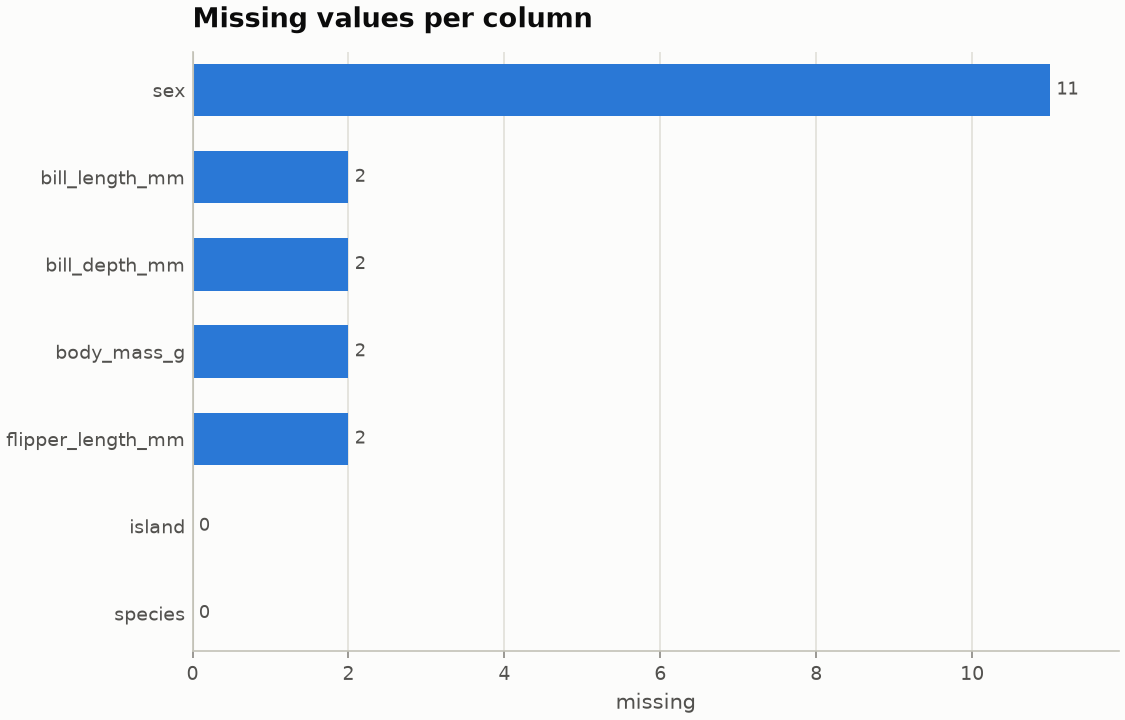

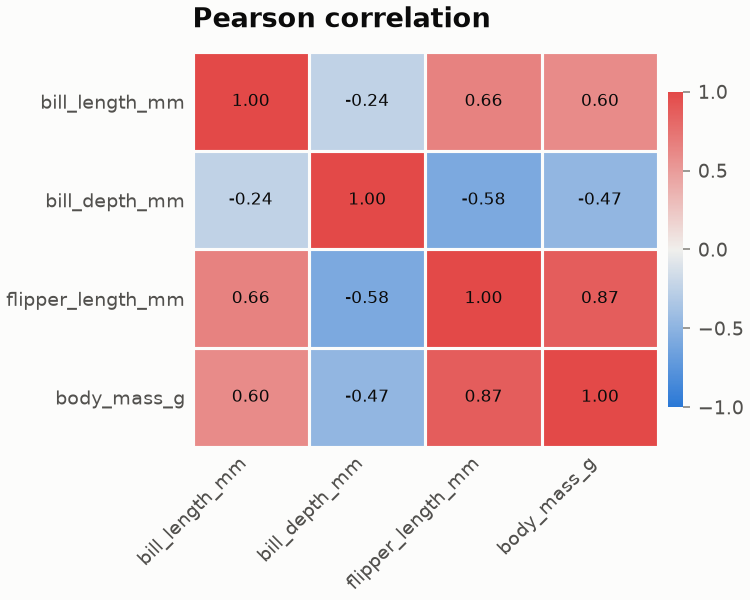

,dtype,kind,missing,unique
species,str,categorical,0,3
island,str,categorical,0,3
bill_length_mm,float64,numerical,2,164
bill_depth_mm,float64,numerical,2,80
flipper_length_mm,float64,numerical,2,55
body_mass_g,float64,numerical,2,94
sex,str,categorical,11,2


In [3]:
pc.eda.overview(pen)

## 1 numerical variable

#### EDA: 1 numerical — body_mass_g

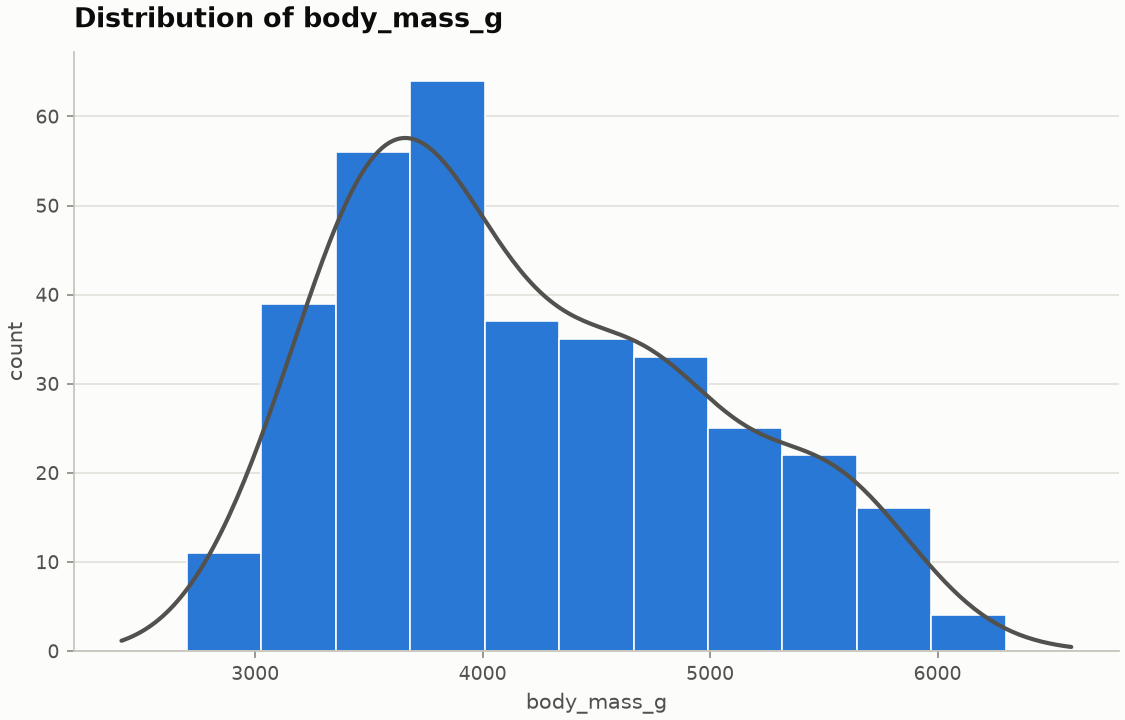

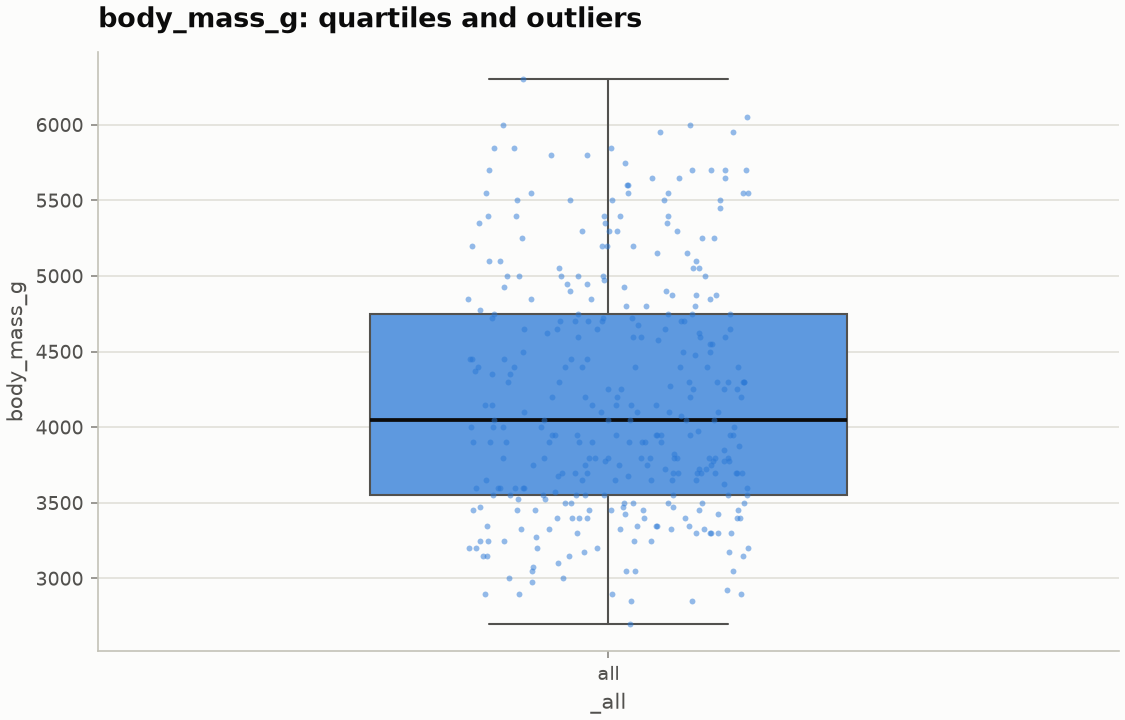

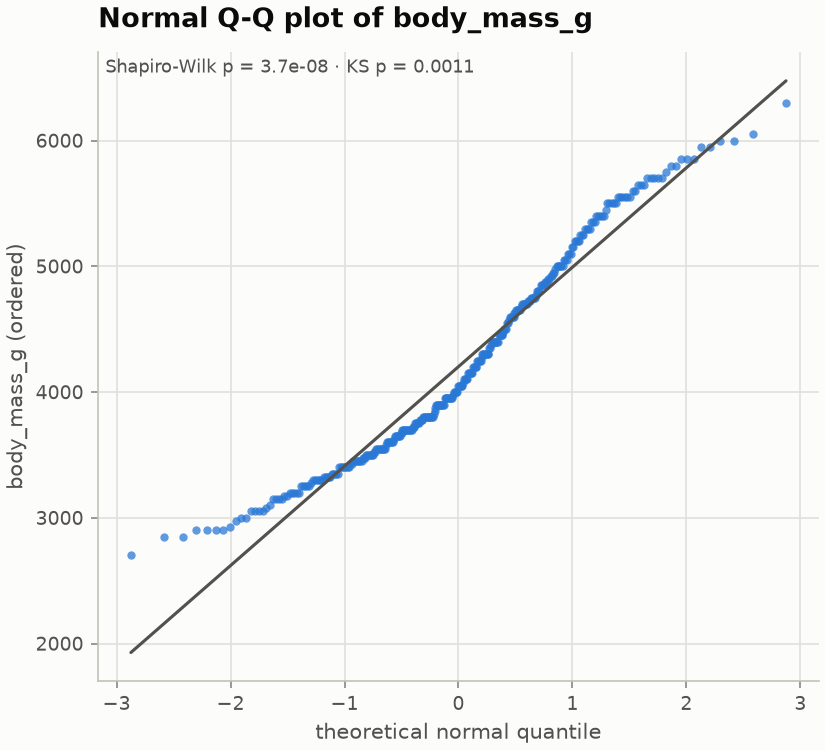

test,statistic,pvalue,effect_name,effect_size,significant,note
Shapiro-Wilk,0.9592,3.679e-08,None,None,True,deviates from normality
Kolmogorov-Smirnov,0.1041,0.001114,None,None,True,deviates from normality


,value
n,342.000000
missing,2.000000
mean,4201.754386
std,801.954536
min,2700.000000
q1,3550.000000
median,4050.000000
q3,4750.000000
max,6300.000000
iqr,1200.000000


In [4]:
pc.eda.analyze(pen, 'body_mass_g')

## 1 categorical variable (is the split uniform?)

#### EDA: 1 categorical — island

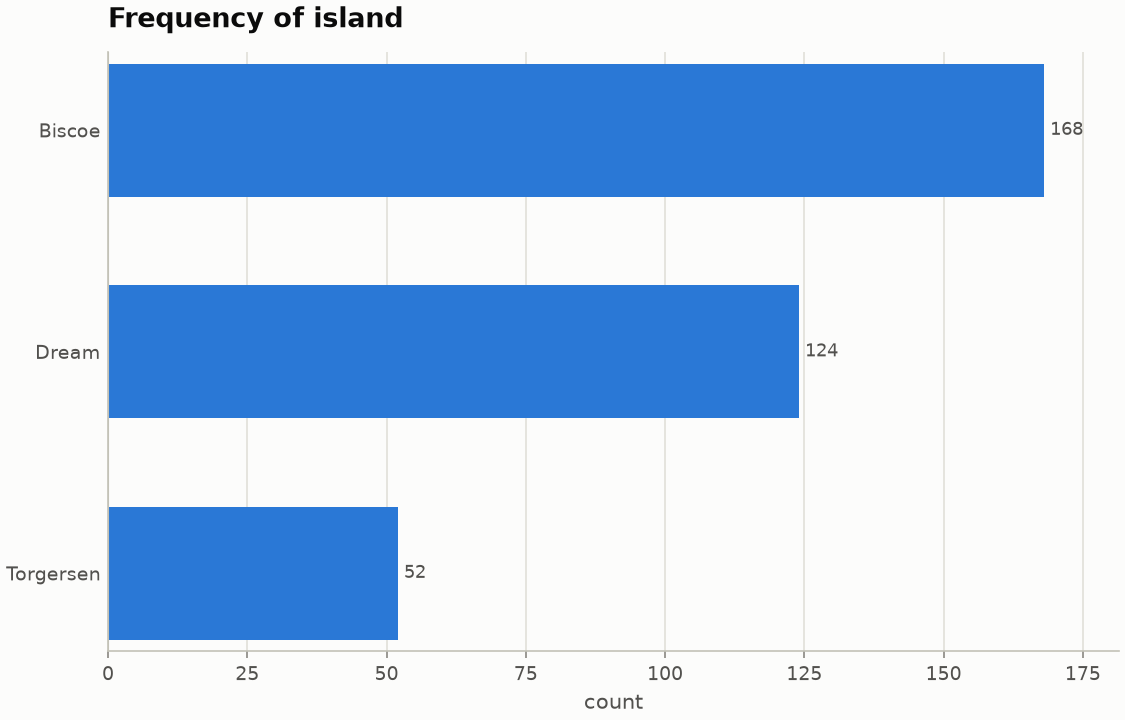

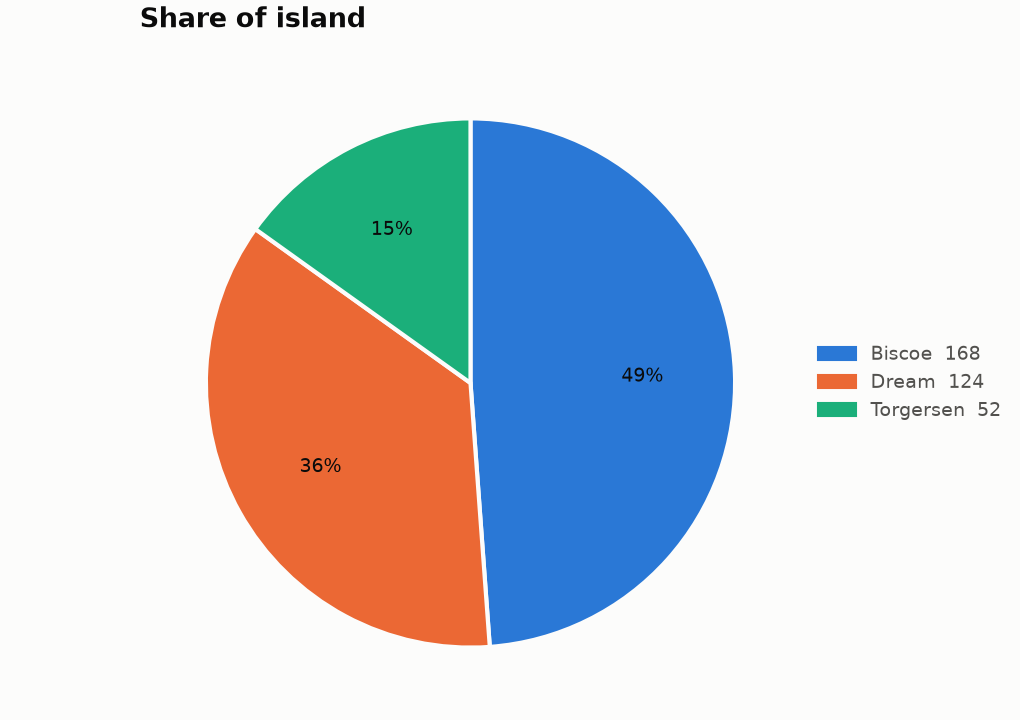

test,statistic,pvalue,effect_name,effect_size,significant,note
Chi-square goodness of fit,59.81,1.027e-13,Cohen's w,0.417,True,frequencies differ from expected


,count,percent
island,,
Biscoe,168,48.837209
Dream,124,36.046512
Torgersen,52,15.116279


In [5]:
pc.eda.analyze(pen, 'island')

## 2 numerical variables

In [6]:
pc.eda.analyze(pen, 'flipper_length_mm', 'body_mass_g', backend='plotly')

#### EDA: 2 numerical — flipper_length_mm, body_mass_g

<Chart kind='scatter' backend='plotly' theme='pychartist', meta=['stats']>

<Chart kind='heatmap' backend='plotly' theme='pychartist', meta=['matrix']>

test,statistic,pvalue,effect_name,effect_size,significant,note
Pearson r,0.8712,4.371e-107,r,0.8712,True,strong positive linear relationship
Spearman rho,0.84,2.763e-92,rho,0.84,True,strong positive monotonic relationship


## Group differences
The recommendation switches to the non-parametric test when any group fails Shapiro-Wilk.

#### EDA: categorical x numerical (3 groups) — species, bill_length_mm

Within-group normality (Shapiro-Wilk): no; Levene p = 0.108. Recommended: Kruskal-Wallis H.

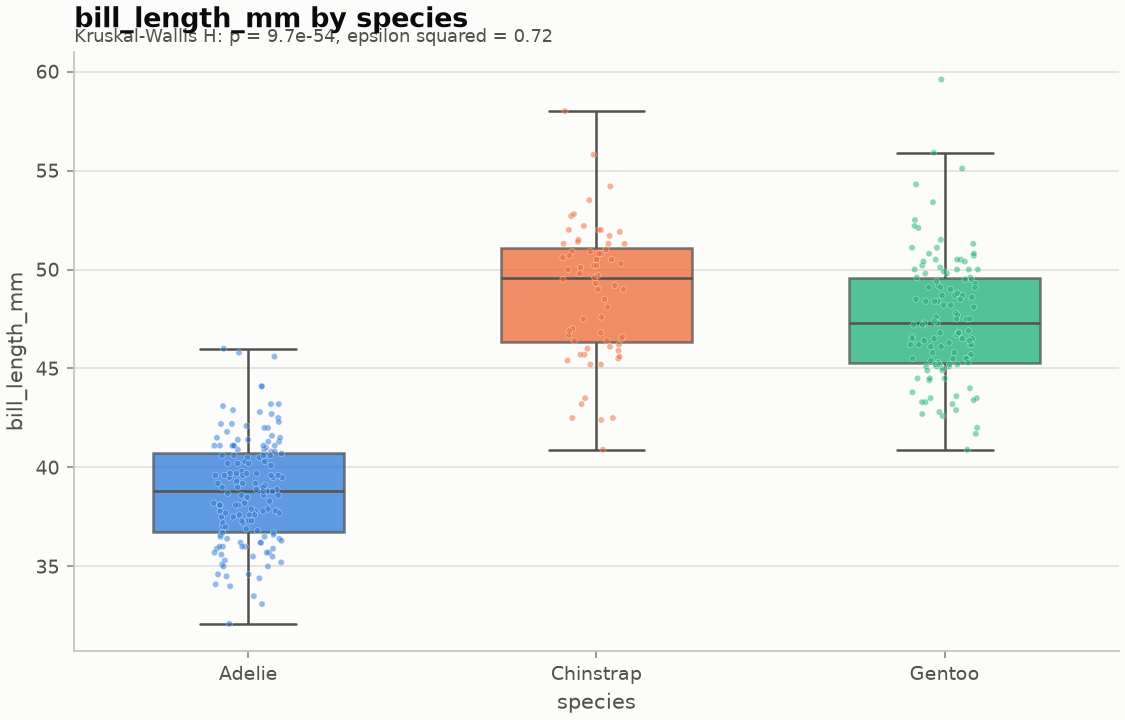

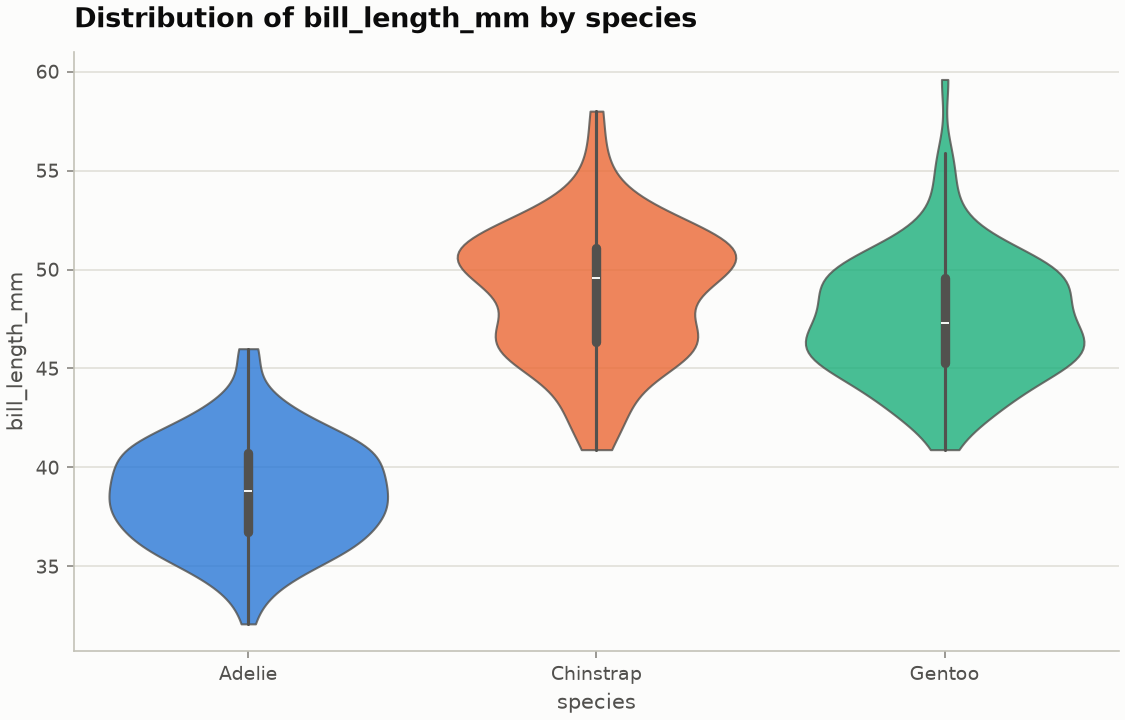

test,statistic,pvalue,effect_name,effect_size,significant,note
One-way ANOVA,410.6,2.695e-91,eta squared,0.7078,True,at least one group mean differs
Kruskal-Wallis H,244.1,9.691e-54,epsilon squared,0.7159,True,at least one group differs in location


,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,151.0,38.791391,2.663405,32.1,36.75,38.80,40.750,46.0
Chinstrap,68.0,48.833824,3.339256,40.9,46.35,49.55,51.075,58.0
Gentoo,123.0,47.504878,3.081857,40.9,45.30,47.30,49.550,59.6


In [7]:
r = pc.eda.analyze(pen, 'species', 'bill_length_mm', backend='seaborn')
r

In [8]:
r.tests

,test,statistic,pvalue,n,alpha,effect_size,effect_name,note,significant,groups
0,One-way ANOVA,410.600255,2.694614e-91,342,0.05,0.707809,eta squared,at least one group mean differs,True,3
1,Kruskal-Wallis H,244.136718,9.691372e-54,342,0.05,0.715943,epsilon squared,at least one group differs in location,True,3


#### EDA: categorical x numerical (2 groups) — sex, body_mass_g

Within-group normality (Shapiro-Wilk): yes; Levene p = 0.0512. Recommended: Welch t-test.

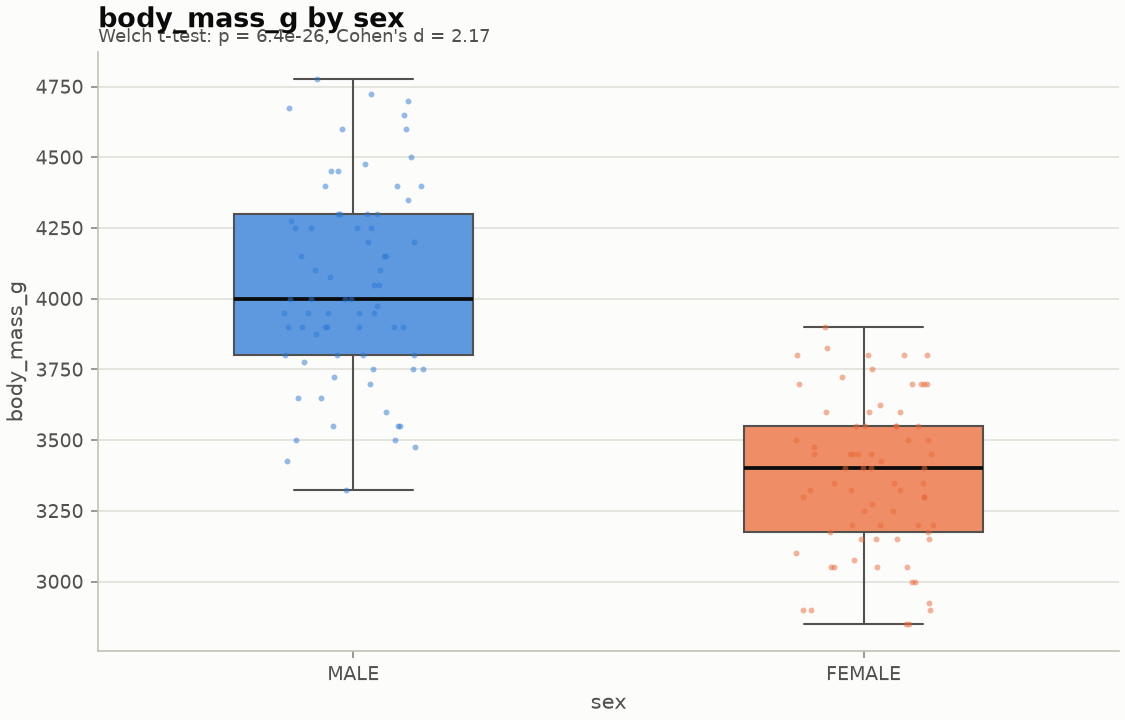

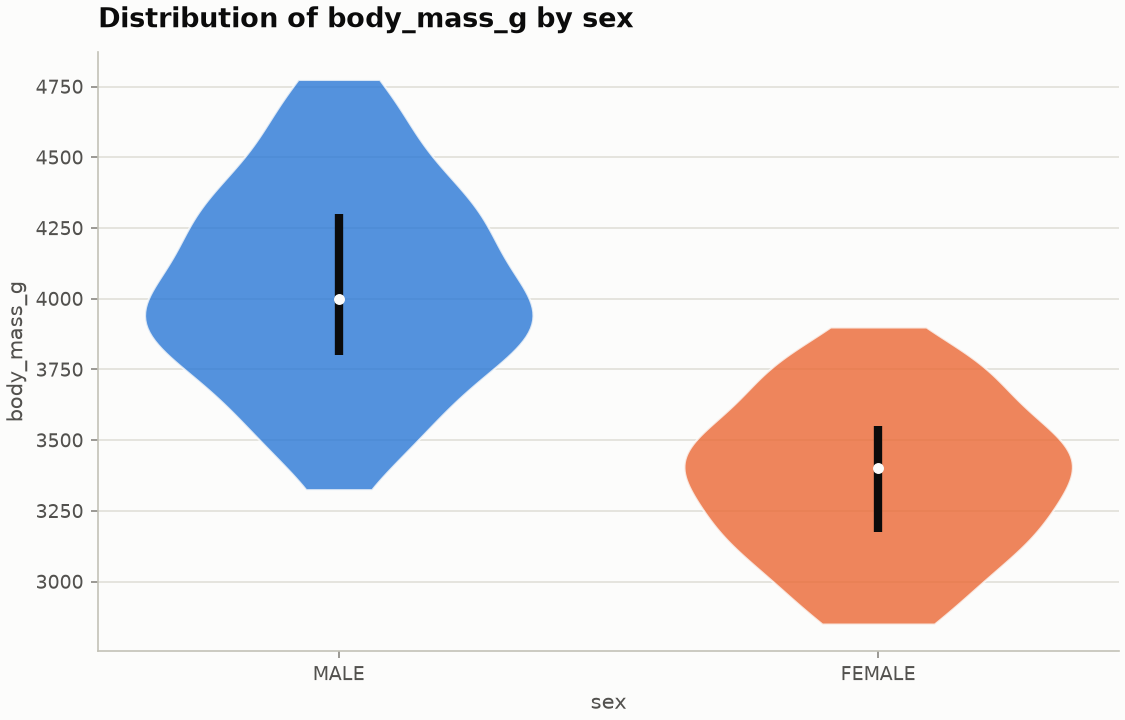

test,statistic,pvalue,effect_name,effect_size,significant,note
Welch t-test,13.13,6.402e-26,Cohen's d,2.173,True,means differ
Mann-Whitney U,5018,3.091e-20,rank-biserial r,-0.8835,True,distributions differ in location


,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
FEMALE,73.0,3368.835616,269.380102,2850.0,3175.0,3400.0,3550.0,3900.0
MALE,73.0,4043.493151,346.811553,3325.0,3800.0,4000.0,4300.0,4775.0


In [9]:
pc.eda.analyze(pen[pen.species == 'Adelie'], 'sex', 'body_mass_g')

## 2 categorical variables

#### EDA: 2 categorical — class, alive

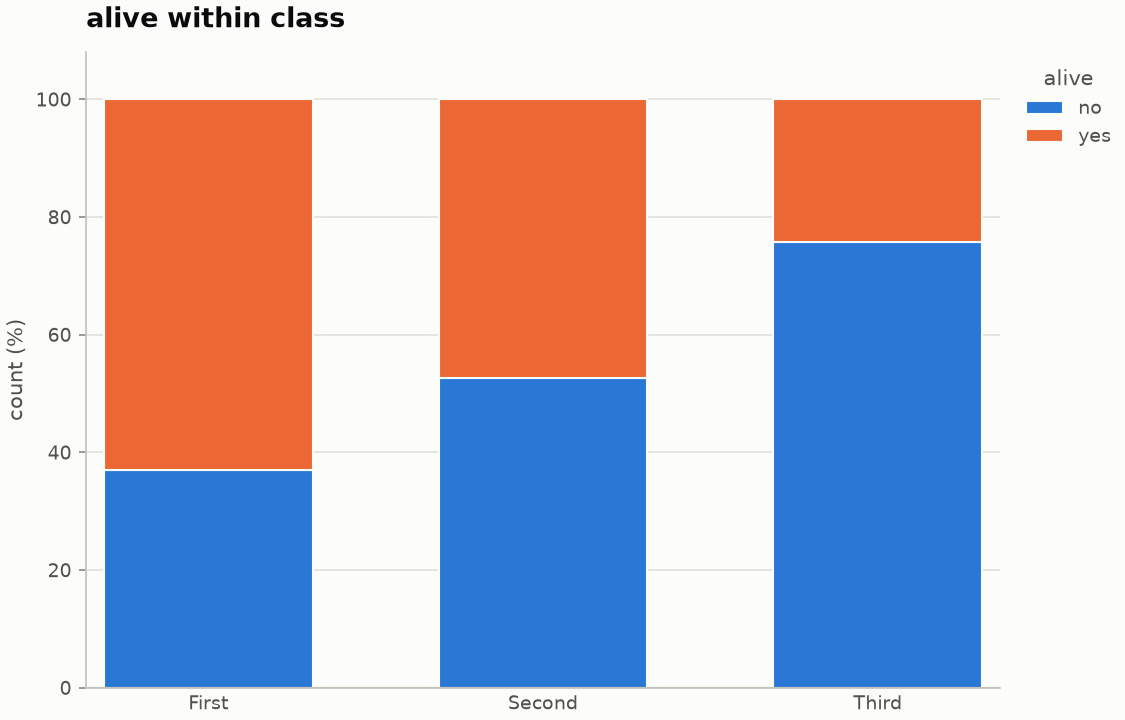

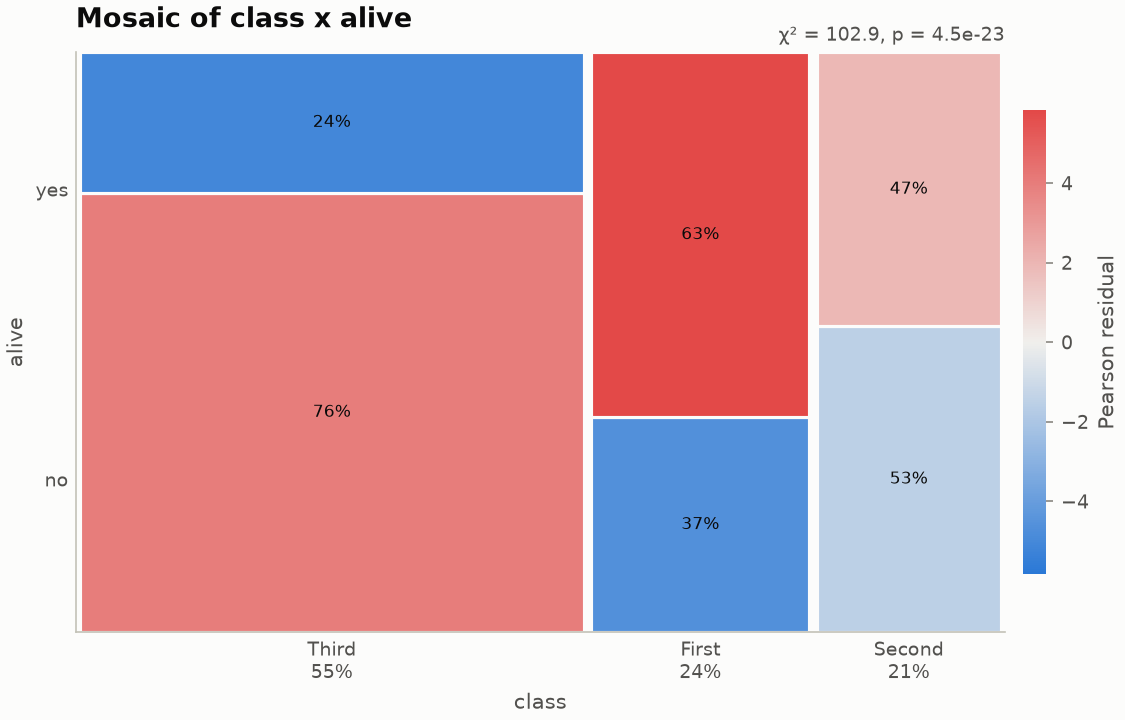

test,statistic,pvalue,effect_name,effect_size,significant,note
Chi-square independence,102.9,4.549e-23,Cramér's V,0.3398,True,variables are associated
Fisher exact,1.652e-25,0.0001,NaN,NaN,True,variables are associated


alive,no,yes,All
class,,,
First,80,136,216
Second,97,87,184
Third,372,119,491
All,549,342,891


In [10]:
pc.eda.analyze(titanic, 'class', 'alive')

## Using the tests directly

In [11]:
from pychartist import stats
print(stats.shapiro_wilk(pen.body_mass_g))
print(stats.chi2_independence(titanic, 'sex', 'alive'))
stats.eda_tests(pen, 'species', 'flipper_length_mm')

Shapiro-Wilk: stat = 0.9592, p = 3.68e-08 (n = 342). deviates from normality
Chi-square independence: stat = 260.7, p = 1.2e-58, Cramér's V = 0.541 (n = 891). variables are associated


,test,statistic,pvalue,n,alpha,effect_size,effect_name,note,significant,groups
0,One-way ANOVA,594.801627,1.351710e-111,342,0.05,0.778229,eta squared,at least one group mean differs,True,3
1,Kruskal-Wallis H,244.890542,6.648053e-54,342,0.05,0.718154,epsilon squared,at least one group differs in location,True,3
